Najdenych suborov: 25
Subory:
  11 kV: 11kV.csv
  12 kV: 12kV.csv
  13 kV: 13kV.csv
  14 kV: 14kV.csv
  15 kV: 15kV.csv
  16 kV: 16kV.csv
  17 kV: 17kV.csv
  18 kV: 18kV.csv
  19 kV: 19kV.csv
  20 kV: 20kV.csv
  21 kV: 21kV.csv
  22 kV: 22kV.csv
  23 kV: 23kV.csv
  24 kV: 24kV.csv
  25 kV: 25kV.csv
  26 kV: 26kV.csv
  27 kV: 27kV.csv
  28 kV: 28kV.csv
  29 kV: 29kV.csv
  30 kV: 30kV.csv
  31 kV: 31kV.csv
  32 kV: 32kV.csv
  33 kV: 33kV.csv
  34 kV: 34kV.csv
  35 kV: 35kV.csv


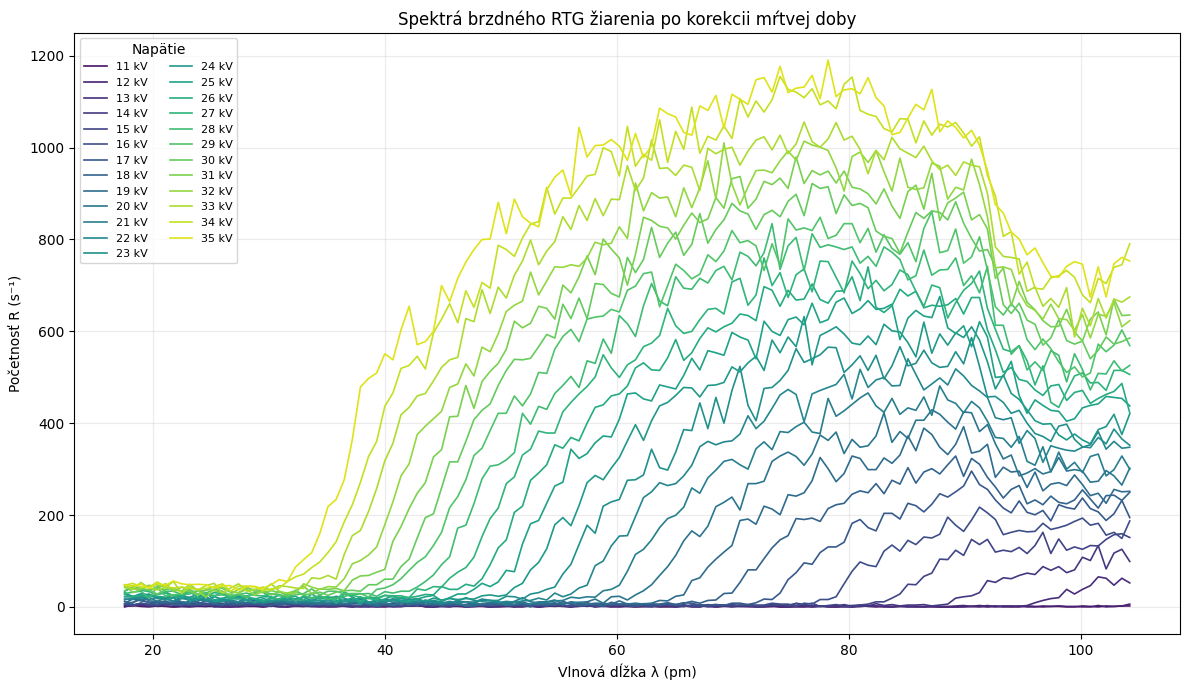

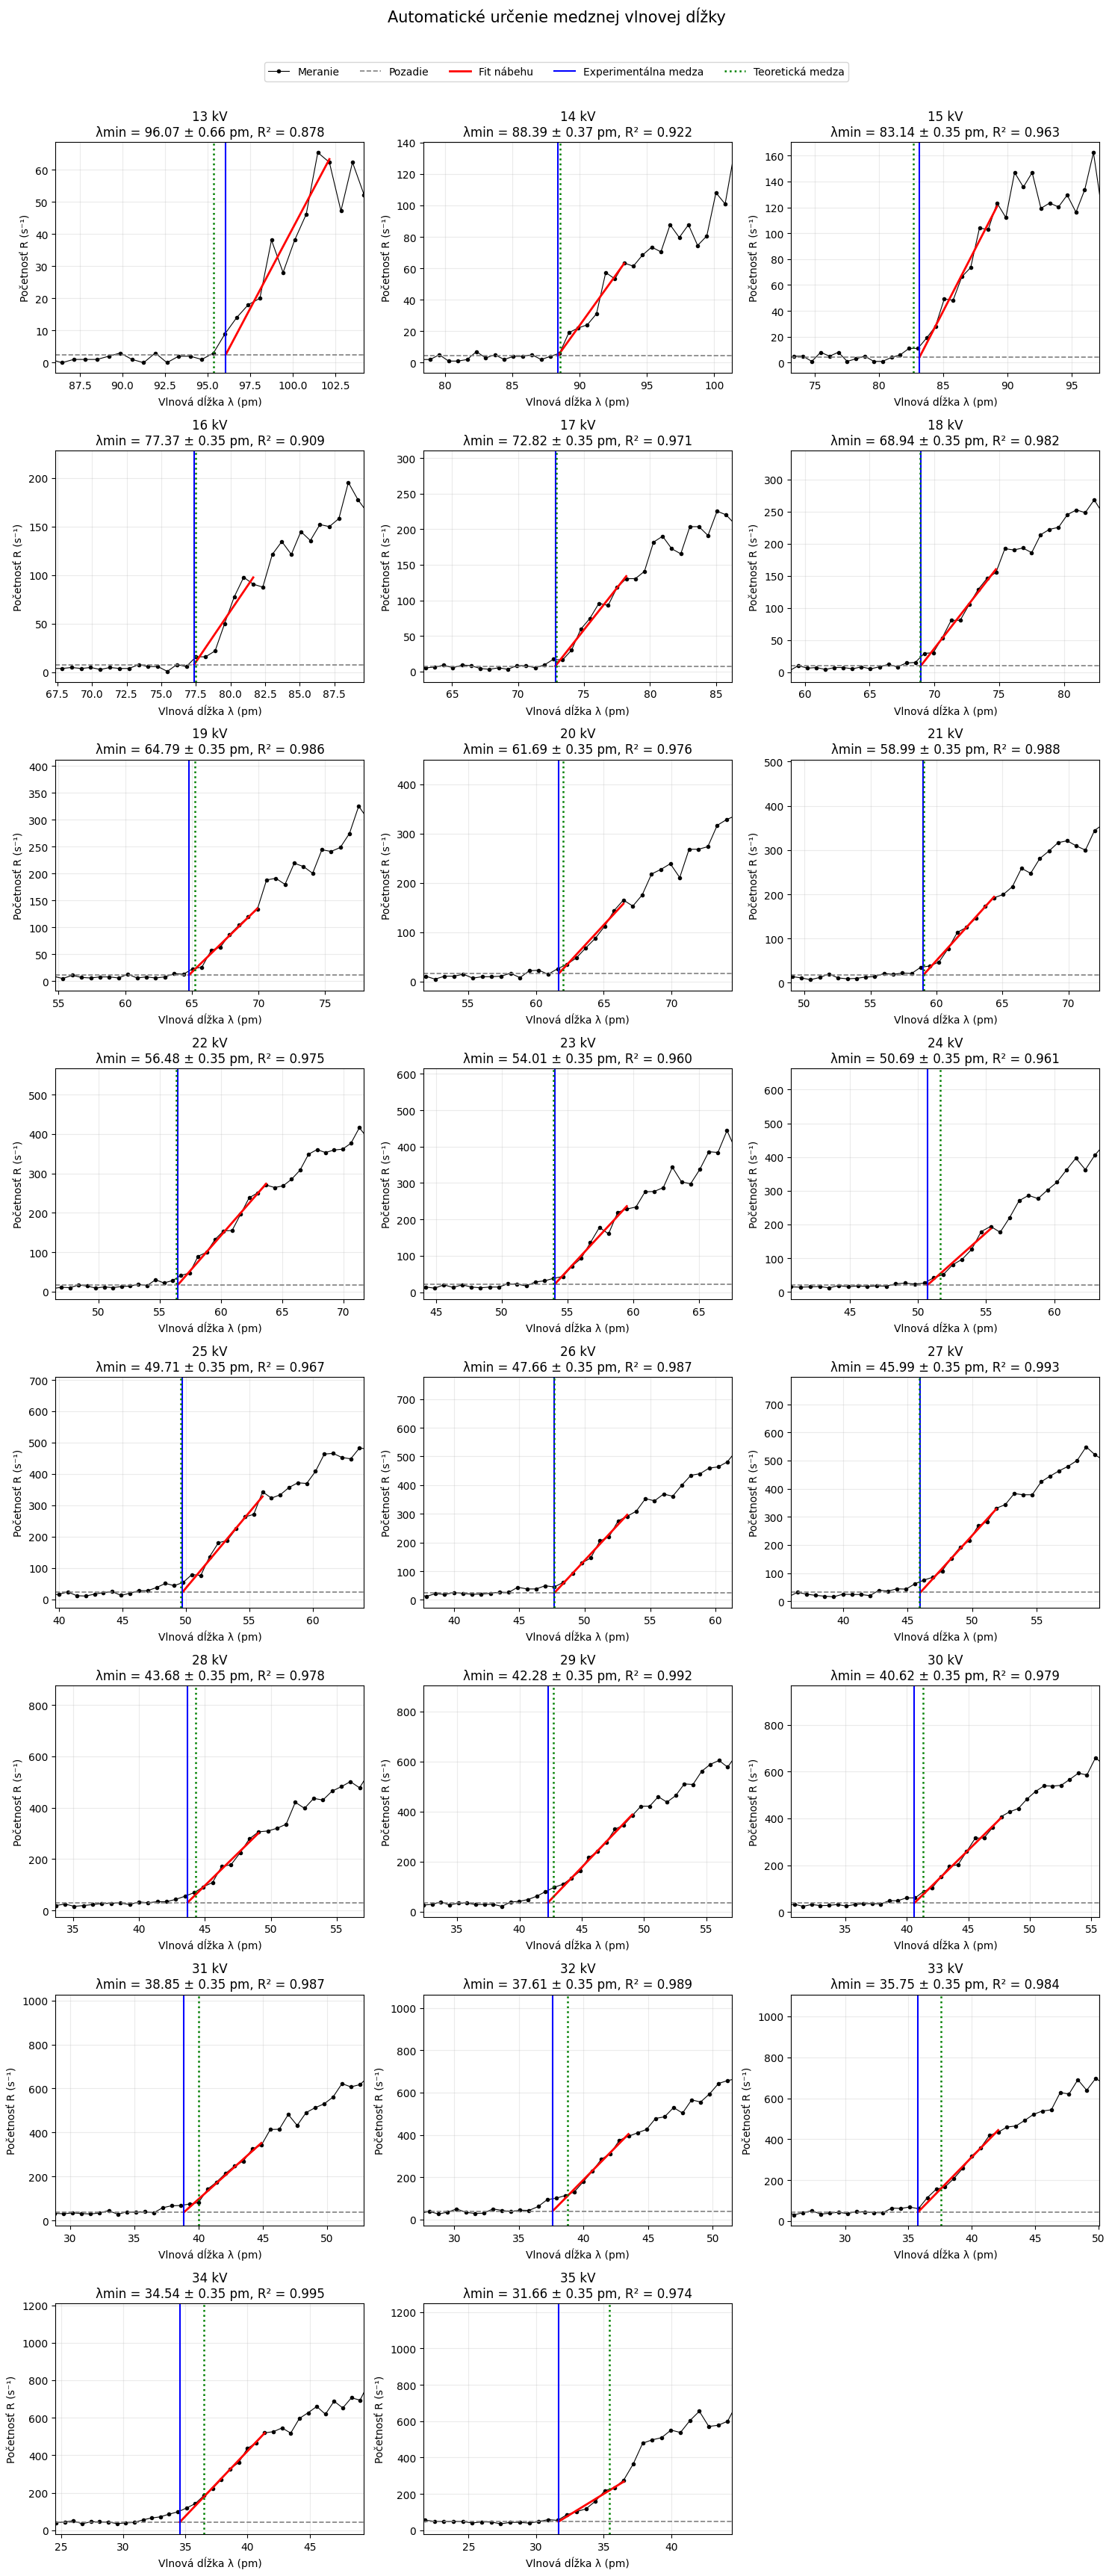

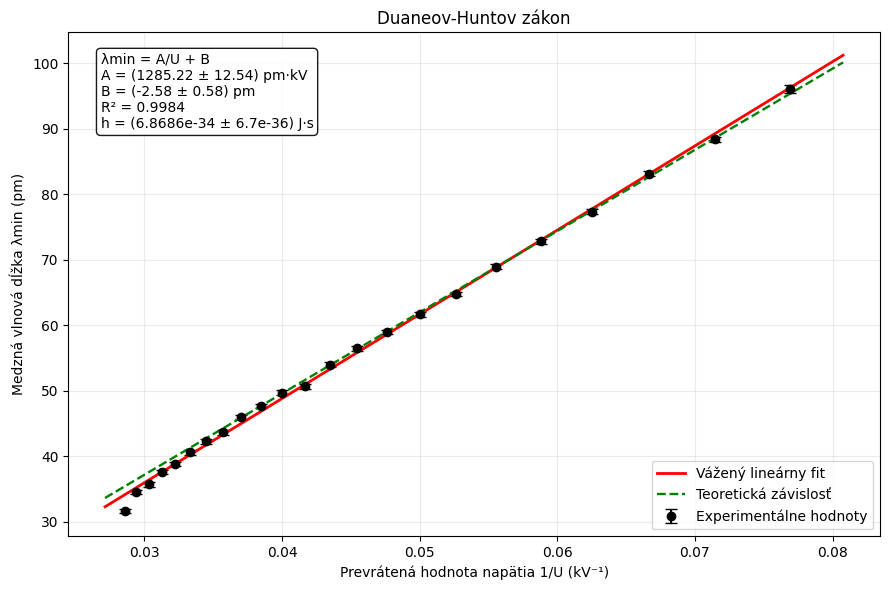


VYSLEDKY URCENIA MEDZNEJ VLNOVEJ DLZKY
 napatie_kV  lambda_exp_pm  u_lambda_pm  lambda_teoria_pm  odchylka_percent  R2_narastu  pouzite_vo_fite                                         poznamka
       35.0         31.656        0.347            35.424            -10.64      0.9735             True                                               OK
       34.0         34.545        0.347            36.466             -5.27      0.9950             True                                               OK
       33.0         35.749        0.347            37.571             -4.85      0.9837             True                                               OK
       32.0         37.608        0.347            38.745             -2.93      0.9888             True                                               OK
       31.0         38.852        0.347            39.995             -2.86      0.9874             True                                               OK
       30.0         40.616        0.

In [4]:
# ============================================================
# SPRACOVANIE BRZDNEHO RTG ZIARENIA
# Subory: 11kV.csv, 12kV.csv, ..., 35kV.csv
#
# Potrebne kniznice:
# numpy, pandas, matplotlib, scipy
# ============================================================

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from scipy.constants import c, e, h
from scipy.stats import linregress


# ============================================================
# 1. NASTAVENIA
# ============================================================

# Priecinok, v ktorom su CSV subory.
# Bodka znamena rovnaky priecinok ako notebook.
PRIECINOK = Path(".")

MIN_NAPATIE_KV = 11
MAX_NAPATIE_KV = 35

# Korekcia na mrtvu dobu detektora
POUZIT_KOREKCIU_MRTVEJ_DOBY = True
MRTVA_DOBA_S = 90e-6

# Pocet bodov pouzitych na odhad pozadia.
# Pri kroku 0,1 stupna zodpoveda 12 bodov intervalu 1,1 stupna.
POCET_BODOV_POZADIA = 12

# Pocet bodov pouzitych na lokalny linearni fit narastu spektra.
POCET_BODOV_NARASTU = 8

# Minimalna pozadovana kvalita linearneho fitu narastu.
MIN_R2_NARASTU = 0.70

# Kolkokrat musi byt maximalna intenzita vacsia ako smerodajna
# odchylka pozadia, aby meranie malo dostatocny signal.
MIN_POMER_SIGNAL_SUM = 5.0

# Ukladanie grafov
UKLADAT_GRAFY = True
PRIECINOK_VYSTUP = PRIECINOK / "vysledky_rtg"

# Ak je True, zobrazia sa diagnosticke grafy urcenia medze
# pre kazde napatie.
ZOBRAZIT_DIAGNOSTIKU = True


# ============================================================
# 2. POMOCNE FUNKCIE
# ============================================================

def napatie_z_nazvu(subor):
    """
    Z nazvu suboru, napr. 35kV.csv, ziska napatie 35 kV.
    """
    zhoda = re.search(r"(\d+(?:[.,]\d+)?)\s*kV", subor.stem, re.IGNORECASE)

    if zhoda is None:
        return None

    return float(zhoda.group(1).replace(",", "."))


def nacitaj_csv(subor):
    """
    Nacita CSV subor z pristroja a odstrani prazdne riadky.

    Ocakavane poradie stlpcov:
    0: cas
    1: napatie
    2: prud
    3: uhol
    4: pocetnost
    5: vlnova dlzka
    6: energia
    7: transmisia
    """

    df = pd.read_csv(
        subor,
        sep=",",
        engine="python",
        skipinitialspace=True
    )

    # Odstranenie uplne prazdnych stlpcov, napr. posledneho
    # stlpca vytvoreneho ciarkou na konci riadka.
    df = df.dropna(axis=1, how="all")

    if df.shape[1] < 7:
        raise ValueError(
            f"Subor {subor.name} ma iba {df.shape[1]} pouzitelnych stlpcov."
        )

    # Pouzijeme poradie stlpcov, pretoze hlavicka obsahuje
    # specialne znaky zapisane pristrojom.
    df = df.iloc[:, :8].copy()

    nazvy = [
        "cas_s",
        "napatie_kV",
        "prud_mA",
        "uhol_deg",
        "pocetnost_1_s",
        "lambda_pm",
        "energia_keV",
        "transmisia_percent"
    ]

    # Ak by v niektorom subore chybal posledny stlpec.
    df.columns = nazvy[:df.shape[1]]

    # Prevod vsetkych hodnot na cisla.
    for stlpec in df.columns:
        df[stlpec] = pd.to_numeric(df[stlpec], errors="coerce")

    # Ponechame iba riadky, kde existuje uhol, pocetnost a vlnova dlzka.
    df = df.dropna(
        subset=["uhol_deg", "pocetnost_1_s", "lambda_pm"]
    ).copy()

    df = df.sort_values("lambda_pm").reset_index(drop=True)

    # Odstranenie pripadnych duplicitnych bodov.
    df = df.drop_duplicates(
        subset=["uhol_deg", "lambda_pm"],
        keep="first"
    ).reset_index(drop=True)

    return df


def korekcia_mrtvej_doby(pocetnost, tau):
    """
    Korekcia neparalyzovatelneho detektora:

        R_skutocna = R_namerana / (1 - R_namerana * tau)

    Ak by bol menovatel nulovy alebo zaporny, vrati NaN.
    """

    pocetnost = np.asarray(pocetnost, dtype=float)
    menovatel = 1.0 - pocetnost * tau

    vysledok = np.full_like(pocetnost, np.nan, dtype=float)
    platne = menovatel > 0

    vysledok[platne] = pocetnost[platne] / menovatel[platne]

    return vysledok


def linearna_funkcia(x, a, b):
    return a * x + b


def r2_hodnota(y, y_fit):
    """
    Koeficient determinacie R^2.
    """
    y = np.asarray(y, dtype=float)
    y_fit = np.asarray(y_fit, dtype=float)

    ss_res = np.sum((y - y_fit) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)

    if ss_tot == 0:
        return np.nan

    return 1.0 - ss_res / ss_tot


def najdi_medzu(df, napatie_kV):
    """
    Automaticke urcenie medznej vlnovej dlzky.

    Postup:
    1. Z prvych bodov odhadne konstantne pozadie.
    2. Prehlada mozne kratke useky narastu spektra.
    3. Kazdy usek prelozi priamkou.
    4. Vypocita priesecnik priamky s pozadim.
    5. Vyberie fyzikalne prijatelny fit s najlepsim skore.
    """

    x = df["lambda_pm"].to_numpy(dtype=float)
    y = df["pocetnost_korigovana"].to_numpy(dtype=float)

    maska = np.isfinite(x) & np.isfinite(y)
    x = x[maska]
    y = y[maska]

    n = len(x)

    if n < POCET_BODOV_POZADIA + POCET_BODOV_NARASTU + 2:
        return {
            "uspech": False,
            "dovod": "Prilis malo platnych bodov."
        }

    # Pozadie z prvych bodov merania.
    y_pozadie_body = y[:POCET_BODOV_POZADIA]
    pozadie = np.median(y_pozadie_body)

    # Robustny odhad sumu pomocou medianovej absolutnej odchylky.
    mad = np.median(np.abs(y_pozadie_body - np.median(y_pozadie_body)))
    sigma_pozadia = 1.4826 * mad

    # Zalozny odhad pri nulovej MAD.
    if not np.isfinite(sigma_pozadia) or sigma_pozadia <= 0:
        sigma_pozadia = np.std(y_pozadie_body, ddof=1)

    if not np.isfinite(sigma_pozadia) or sigma_pozadia <= 0:
        sigma_pozadia = np.sqrt(max(pozadie, 1.0))

    amplituda = np.nanmax(y) - pozadie
    pomer_signal_sum = amplituda / sigma_pozadia

    if pomer_signal_sum < MIN_POMER_SIGNAL_SUM:
        return {
            "uspech": False,
            "dovod": "Signal nie je dostatocne vyrazny oproti pozadiu.",
            "pozadie": pozadie,
            "sigma_pozadia": sigma_pozadia,
            "pomer_signal_sum": pomer_signal_sum
        }

    kandidati = []

    # Prvy fit narastu nemoze zacinat priamo v oblasti pozadia.
    prvy_index = max(POCET_BODOV_POZADIA - 3, 3)
    posledny_index = n - POCET_BODOV_NARASTU

    for zaciatok in range(prvy_index, posledny_index + 1):

        koniec = zaciatok + POCET_BODOV_NARASTU

        x_fit = x[zaciatok:koniec]
        y_fit = y[zaciatok:koniec]

        if len(x_fit) < 3:
            continue

        try:
            parametre, kovariancia = curve_fit(
                linearna_funkcia,
                x_fit,
                y_fit
            )
        except Exception:
            continue

        smernica, posun = parametre

        if not np.isfinite(smernica) or smernica <= 0:
            continue

        predikcia = linearna_funkcia(x_fit, smernica, posun)
        r2 = r2_hodnota(y_fit, predikcia)

        if not np.isfinite(r2) or r2 < MIN_R2_NARASTU:
            continue

        # Priesecnik narastovej priamky s urovnou pozadia.
        lambda_min = (pozadie - posun) / smernica

        if not np.isfinite(lambda_min):
            continue

        krok = np.median(np.diff(x))

        # Priesecnik ma lezat tesne pred alebo na zaciatku
        # fitovaneho useku, nie daleko mimo neho.
        spodna_medza = x_fit[0] - 4.0 * krok
        horna_medza = x_fit[-1]

        if not (spodna_medza <= lambda_min <= horna_medza):
            continue

        # Narast na konci fitovaneho useku musi byt vyrazne nad pozadim.
        if y_fit[-1] < pozadie + 3.0 * sigma_pozadia:
            continue

        rezidua = y_fit - predikcia
        rmse = np.sqrt(np.mean(rezidua**2))

        # Skore zvyhodnuje vysoke R^2, velku smernicu a maly rozptyl.
        skore = (
            r2
            * smernica
            / (rmse + sigma_pozadia + 1e-12)
        )

        # Odhad neistoty priesecnika Monte Carlo metodou
        # z kovariancnej matice parametrov fitu.
        sigma_lambda = np.nan

        if (
            kovariancia.shape == (2, 2)
            and np.all(np.isfinite(kovariancia))
        ):
            rng = np.random.default_rng(12345)

            try:
                vzorky = rng.multivariate_normal(
                    mean=parametre,
                    cov=kovariancia,
                    size=5000
                )

                a_vzorky = vzorky[:, 0]
                b_vzorky = vzorky[:, 1]

                platne = (
                    np.isfinite(a_vzorky)
                    & np.isfinite(b_vzorky)
                    & (a_vzorky > 0)
                )

                lambda_vzorky = (
                    pozadie - b_vzorky[platne]
                ) / a_vzorky[platne]

                lambda_vzorky = lambda_vzorky[
                    np.isfinite(lambda_vzorky)
                ]

                if len(lambda_vzorky) > 20:
                    sigma_lambda = np.std(lambda_vzorky, ddof=1)

            except Exception:
                pass

        # Minimalna realisticka neistota je priblizne polovica
        # kroku merania vo vlnovej dlzke.
        minimalna_neistota = krok / 2.0

        if not np.isfinite(sigma_lambda):
            sigma_lambda = minimalna_neistota
        else:
            sigma_lambda = max(sigma_lambda, minimalna_neistota)

        kandidati.append({
            "lambda_min_pm": lambda_min,
            "sigma_lambda_pm": sigma_lambda,
            "smernica": smernica,
            "posun": posun,
            "r2_narastu": r2,
            "rmse": rmse,
            "skore": skore,
            "zaciatok": zaciatok,
            "koniec": koniec,
            "x_fit": x_fit,
            "y_fit": y_fit,
            "y_pred": predikcia
        })

    if not kandidati:
        return {
            "uspech": False,
            "dovod": "Nenasiel sa spolahlivy linearni usek narastu.",
            "pozadie": pozadie,
            "sigma_pozadia": sigma_pozadia,
            "pomer_signal_sum": pomer_signal_sum
        }

    # Vyber najlepsieho kandidata.
    najlepsi = max(kandidati, key=lambda kandidat: kandidat["skore"])

    # Teoreticka hodnota sa pouziva iba na porovnanie,
    # nie na samotne automaticke hladanie medze.
    lambda_teoria_pm = (h * c / (e * napatie_kV * 1000.0)) * 1e12

    najlepsi.update({
        "uspech": True,
        "dovod": "OK",
        "pozadie": pozadie,
        "sigma_pozadia": sigma_pozadia,
        "pomer_signal_sum": pomer_signal_sum,
        "lambda_teoria_pm": lambda_teoria_pm,
        "odchylka_percent": (
            100.0
            * (najlepsi["lambda_min_pm"] - lambda_teoria_pm)
            / lambda_teoria_pm
        ),
        "x_vsetky": x,
        "y_vsetky": y
    })

    return najlepsi


# ============================================================
# 3. NAJDENIE A NACITANIE SUBOROV
# ============================================================

subory = []

for subor in PRIECINOK.glob("*.csv"):
    napatie = napatie_z_nazvu(subor)

    if napatie is None:
        continue

    if MIN_NAPATIE_KV <= napatie <= MAX_NAPATIE_KV:
        subory.append((napatie, subor))

subory.sort(key=lambda dvojica: dvojica[0])

if len(subory) == 0:
    raise FileNotFoundError(
        "Nenasiel sa ziaden subor typu 11kV.csv az 35kV.csv.\n"
        "Skontroluj hodnotu premennej PRIECINOK."
    )

print(f"Najdenych suborov: {len(subory)}")
print("Subory:")

for napatie, subor in subory:
    print(f"  {napatie:g} kV: {subor.name}")

if UKLADAT_GRAFY:
    PRIECINOK_VYSTUP.mkdir(parents=True, exist_ok=True)


merania = {}

for napatie_nazov, subor in subory:

    df = nacitaj_csv(subor)

    if len(df) == 0:
        warnings.warn(f"Subor {subor.name} neobsahuje platne meranie.")
        continue

    # Kontrola napatia ulozeneho priamo v CSV.
    if "napatie_kV" in df.columns:
        napatie_csv = df["napatie_kV"].dropna()

        if len(napatie_csv) > 0:
            napatie_csv = float(np.median(napatie_csv))

            if abs(napatie_csv - napatie_nazov) > 0.2:
                warnings.warn(
                    f"V subore {subor.name} je napatie "
                    f"{napatie_csv:.2f} kV, ale nazov udava "
                    f"{napatie_nazov:.2f} kV."
                )

    df["pocetnost_namerana"] = df["pocetnost_1_s"]

    if POUZIT_KOREKCIU_MRTVEJ_DOBY:
        df["pocetnost_korigovana"] = korekcia_mrtvej_doby(
            df["pocetnost_namerana"],
            MRTVA_DOBA_S
        )
    else:
        df["pocetnost_korigovana"] = df["pocetnost_namerana"]

    merania[napatie_nazov] = df


if len(merania) == 0:
    raise RuntimeError("Nepodarilo sa nacitat ziadne platne meranie.")


# ============================================================
# 4. GRAF VSETKYCH SPEKTIER
# ============================================================

plt.figure(figsize=(12, 7))

farby = plt.cm.viridis(
    np.linspace(0.05, 0.95, len(merania))
)

for farba, (napatie, df) in zip(farby, sorted(merania.items())):

    plt.plot(
        df["lambda_pm"],
        df["pocetnost_korigovana"],
        color=farba,
        linewidth=1.2,
        label=f"{napatie:g} kV"
    )

plt.xlabel("Vlnová dĺžka λ (pm)")
plt.ylabel("Početnosť R (s⁻¹)")

if POUZIT_KOREKCIU_MRTVEJ_DOBY:
    plt.title("Spektrá brzdného RTG žiarenia po korekcii mŕtvej doby")
else:
    plt.title("Spektrá brzdného RTG žiarenia")

plt.grid(alpha=0.25)

# Legenda v niekolkych stlpcoch, aby nezaberala cely graf.
plt.legend(
    title="Napätie",
    ncol=2,
    fontsize=8,
    frameon=True
)

plt.tight_layout()

if UKLADAT_GRAFY:
    plt.savefig(
        PRIECINOK_VYSTUP / "01_vsetky_spektra.png",
        dpi=300,
        bbox_inches="tight"
    )

plt.show()


# ============================================================
# 5. URCENIE MEDZNYCH VLNOVYCH DLZOK
# ============================================================

vysledky = []
diagnostika = {}

for napatie, df in sorted(merania.items()):

    vysledok = najdi_medzu(df, napatie)
    diagnostika[napatie] = vysledok

    lambda_teoria_pm = (
        h * c / (e * napatie * 1000.0)
    ) * 1e12

    # Kontrola, ci teoreticka medza vobec lezi v rozsahu merania.
    lambda_min_merania = df["lambda_pm"].min()
    lambda_max_merania = df["lambda_pm"].max()

    medza_v_rozsahu = (
        lambda_min_merania
        <= lambda_teoria_pm
        <= lambda_max_merania
    )

    if vysledok["uspech"]:

        vysledky.append({
            "napatie_kV": napatie,
            "1_U_1_kV": 1.0 / napatie,
            "lambda_exp_pm": vysledok["lambda_min_pm"],
            "u_lambda_pm": vysledok["sigma_lambda_pm"],
            "lambda_teoria_pm": lambda_teoria_pm,
            "odchylka_percent": vysledok["odchylka_percent"],
            "R2_narastu": vysledok["r2_narastu"],
            "medza_v_rozsahu": medza_v_rozsahu,
            "pouzite_vo_fite": (
                medza_v_rozsahu
                and vysledok["r2_narastu"] >= MIN_R2_NARASTU
            ),
            "poznamka": "OK" if medza_v_rozsahu else
                        "Teoreticka medza je mimo rozsahu merania"
        })

    else:

        vysledky.append({
            "napatie_kV": napatie,
            "1_U_1_kV": 1.0 / napatie,
            "lambda_exp_pm": np.nan,
            "u_lambda_pm": np.nan,
            "lambda_teoria_pm": lambda_teoria_pm,
            "odchylka_percent": np.nan,
            "R2_narastu": np.nan,
            "medza_v_rozsahu": medza_v_rozsahu,
            "pouzite_vo_fite": False,
            "poznamka": vysledok["dovod"]
        })


vysledky_df = pd.DataFrame(vysledky)
vysledky_df = vysledky_df.sort_values(
    "napatie_kV",
    ascending=False
).reset_index(drop=True)


# ============================================================
# 6. DIAGNOSTICKE GRAFY URCENIA MEDZE
# ============================================================

if ZOBRAZIT_DIAGNOSTIKU:

    uspesne_napatia = [
        napatie
        for napatie, vysledok in diagnostika.items()
        if vysledok["uspech"]
    ]

    pocet = len(uspesne_napatia)

    if pocet > 0:

        pocet_stlpcov = 3
        pocet_riadkov = int(np.ceil(pocet / pocet_stlpcov))

        fig, axes = plt.subplots(
            pocet_riadkov,
            pocet_stlpcov,
            figsize=(15, 4.2 * pocet_riadkov)
        )

        axes = np.atleast_1d(axes).ravel()

        for ax, napatie in zip(axes, uspesne_napatia):

            vysledok = diagnostika[napatie]

            x = vysledok["x_vsetky"]
            y = vysledok["y_vsetky"]

            ax.plot(
                x,
                y,
                "o-",
                markersize=3,
                linewidth=0.8,
                color="black",
                label="Meranie"
            )

            ax.axhline(
                vysledok["pozadie"],
                color="gray",
                linestyle="--",
                linewidth=1.2,
                label="Pozadie"
            )

            x_priamka = np.linspace(
                vysledok["lambda_min_pm"],
                vysledok["x_fit"][-1],
                100
            )

            y_priamka = linearna_funkcia(
                x_priamka,
                vysledok["smernica"],
                vysledok["posun"]
            )

            ax.plot(
                x_priamka,
                y_priamka,
                color="red",
                linewidth=2,
                label="Fit nábehu"
            )

            ax.axvline(
                vysledok["lambda_min_pm"],
                color="blue",
                linestyle="-",
                linewidth=1.5,
                label="Experimentálna medza"
            )

            ax.axvline(
                vysledok["lambda_teoria_pm"],
                color="green",
                linestyle=":",
                linewidth=1.8,
                label="Teoretická medza"
            )

            # Zobrazi sa iba oblast okolo medze.
            dolny_limit = max(
                x.min(),
                vysledok["lambda_min_pm"] - 10
            )

            horny_limit = min(
                x.max(),
                vysledok["x_fit"][-1] + 8
            )

            ax.set_xlim(dolny_limit, horny_limit)

            ax.set_title(
                f"{napatie:g} kV\n"
                f"λmin = {vysledok['lambda_min_pm']:.2f} "
                f"± {vysledok['sigma_lambda_pm']:.2f} pm, "
                f"R² = {vysledok['r2_narastu']:.3f}"
            )

            ax.set_xlabel("Vlnová dĺžka λ (pm)")
            ax.set_ylabel("Početnosť R (s⁻¹)")
            ax.grid(alpha=0.25)

        # Vypnutie nepouzitych osi.
        for ax in axes[pocet:]:
            ax.axis("off")

        handles, labels = axes[0].get_legend_handles_labels()

        fig.legend(
            handles,
            labels,
            loc="upper center",
            ncol=5,
            bbox_to_anchor=(0.5, 1.005)
        )

        fig.suptitle(
            "Automatické určenie medznej vlnovej dĺžky",
            fontsize=15,
            y=1.025
        )

        plt.tight_layout()

        if UKLADAT_GRAFY:
            plt.savefig(
                PRIECINOK_VYSTUP / "02_diagnostika_medzi.png",
                dpi=250,
                bbox_inches="tight"
            )

        plt.show()


# ============================================================
# 7. LINEARNY FIT LAMBDA_MIN = A * (1/U) + B
# ============================================================

fit_data = vysledky_df[
    vysledky_df["pouzite_vo_fite"]
    & np.isfinite(vysledky_df["lambda_exp_pm"])
    & np.isfinite(vysledky_df["u_lambda_pm"])
].copy()


if len(fit_data) < 3:
    print("\nNedostatok spolahlivych bodov na linearny fit.")
    print("Planckova konstanta sa nevypocitala.")

    fit_uspesny = False

else:
    fit_uspesny = True

    x_fit = fit_data["1_U_1_kV"].to_numpy(dtype=float, copy=True)
    y_fit = fit_data["lambda_exp_pm"].to_numpy(dtype=float, copy=True)
    sigma_fit = fit_data["u_lambda_pm"].to_numpy(dtype=float, copy=True)

    # Ochrana pred nulovou neistotou.
    kladne_neistoty = sigma_fit[sigma_fit > 0]

    if len(kladne_neistoty) == 0:
        sigma_fit[:] = 1.0
    else:
        minimum = np.min(kladne_neistoty)
        sigma_fit[sigma_fit <= 0] = minimum

    # Vazeny linearni fit.
    koeficienty, kovariancia = np.polyfit(
        x_fit,
        y_fit,
        deg=1,
        w=1.0 / sigma_fit,
        cov=True
    )

    A_pm_kV = koeficienty[0]
    B_pm = koeficienty[1]

    u_A_pm_kV = np.sqrt(kovariancia[0, 0])
    u_B_pm = np.sqrt(kovariancia[1, 1])

    y_pred = A_pm_kV * x_fit + B_pm
    R2_celkom = r2_hodnota(y_fit, y_pred)

    # Prevod smernice:
    #
    # lambda = h*c/(e*U)
    #
    # Ak je lambda v pm a U v kV:
    # A ma jednotku pm*kV.
    #
    # 1 pm*kV = 10^(-12) m * 10^3 V = 10^(-9) m*V
    #
    # h_exp = A * e / c
    h_exp = A_pm_kV * 1e-9 * e / c
    u_h_exp = u_A_pm_kV * 1e-9 * e / c

    odchylka_h_percent = 100.0 * (h_exp - h) / h

    # Vypocet redukovaneho chi-kvadrat.
    rezidua = y_fit - y_pred
    chi2 = np.sum((rezidua / sigma_fit) ** 2)
    stupne_volnosti = len(x_fit) - 2

    if stupne_volnosti > 0:
        redukovane_chi2 = chi2 / stupne_volnosti
    else:
        redukovane_chi2 = np.nan

    # Graf lambda_min proti 1/U.
    x_ciara = np.linspace(
        0.95 * x_fit.min(),
        1.05 * x_fit.max(),
        300
    )

    y_ciara = A_pm_kV * x_ciara + B_pm

    plt.figure(figsize=(9, 6))

    plt.errorbar(
        x_fit,
        y_fit,
        yerr=sigma_fit,
        fmt="o",
        capsize=4,
        color="black",
        label="Experimentálne hodnoty"
    )

    plt.plot(
        x_ciara,
        y_ciara,
        color="red",
        linewidth=2,
        label="Vážený lineárny fit"
    )

    # Teoreticka zavislost bez absolutneho clena.
    A_teoria_pm_kV = (h * c / e) * 1e9
    y_teoria = A_teoria_pm_kV * x_ciara

    plt.plot(
        x_ciara,
        y_teoria,
        color="green",
        linestyle="--",
        linewidth=1.7,
        label="Teoretická závislosť"
    )

    plt.xlabel("Prevrátená hodnota napätia 1/U (kV⁻¹)")
    plt.ylabel("Medzná vlnová dĺžka λmin (pm)")
    plt.title("Duaneov-Huntov zákon")
    plt.grid(alpha=0.25)
    plt.legend()

    text = (
        f"λmin = A/U + B\n"
        f"A = ({A_pm_kV:.2f} ± {u_A_pm_kV:.2f}) pm·kV\n"
        f"B = ({B_pm:.2f} ± {u_B_pm:.2f}) pm\n"
        f"R² = {R2_celkom:.4f}\n"
        f"h = ({h_exp:.4e} ± {u_h_exp:.1e}) J·s"
    )

    plt.text(
        0.04,
        0.96,
        text,
        transform=plt.gca().transAxes,
        va="top",
        ha="left",
        bbox={
            "boxstyle": "round",
            "facecolor": "white",
            "alpha": 0.9
        }
    )

    plt.tight_layout()

    if UKLADAT_GRAFY:
        plt.savefig(
            PRIECINOK_VYSTUP / "03_duane_hunt_fit.png",
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()


# ============================================================
# 8. VYPIS VYSLEDKOV
# ============================================================

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 180)

tabulka_na_vypis = vysledky_df.copy()

stlpce_zaokruhlenie = {
    "napatie_kV": 1,
    "1_U_1_kV": 6,
    "lambda_exp_pm": 3,
    "u_lambda_pm": 3,
    "lambda_teoria_pm": 3,
    "odchylka_percent": 2,
    "R2_narastu": 4
}

tabulka_na_vypis = tabulka_na_vypis.round(stlpce_zaokruhlenie)

print("\n" + "=" * 110)
print("VYSLEDKY URCENIA MEDZNEJ VLNOVEJ DLZKY")
print("=" * 110)

print(
    tabulka_na_vypis[
        [
            "napatie_kV",
            "lambda_exp_pm",
            "u_lambda_pm",
            "lambda_teoria_pm",
            "odchylka_percent",
            "R2_narastu",
            "pouzite_vo_fite",
            "poznamka"
        ]
    ].to_string(index=False)
)


if fit_uspesny:

    print("\n" + "=" * 75)
    print("VYSLEDOK LINEARNEHO FITU")
    print("=" * 75)

    print(
        f"Smernica A:              "
        f"{A_pm_kV:.4f} ± {u_A_pm_kV:.4f} pm·kV"
    )

    print(
        f"Absolutny clen B:        "
        f"{B_pm:.4f} ± {u_B_pm:.4f} pm"
    )

    print(f"Koeficient R²:           {R2_celkom:.6f}")

    print(
        f"Redukovane chi-kvadrat:  "
        f"{redukovane_chi2:.4f}"
    )

    print(
        f"\nExperimentálna h:        "
        f"({h_exp:.6e} ± {u_h_exp:.2e}) J·s"
    )

    print(
        f"Tabuľková h:             "
        f"{h:.6e} J·s"
    )

    print(
        f"Relatívna odchýlka h:    "
        f"{odchylka_h_percent:.2f} %"
    )

    print(
        f"Počet bodov vo fite:     "
        f"{len(fit_data)}"
    )


# ============================================================
# 9. ULOZENIE TABULIEK
# ============================================================

if UKLADAT_GRAFY:

    cesta_csv = PRIECINOK_VYSTUP / "vysledky_medzne_vlnove_dlzky.csv"

    vysledky_df.to_csv(
        cesta_csv,
        index=False,
        encoding="utf-8-sig"
    )

    print("\nVýsledky boli uložené do priečinka:")
    print(PRIECINOK_VYSTUP.resolve())

    print("\nVytvorené súbory:")
    print("  01_vsetky_spektra.png")
    print("  02_diagnostika_medzi.png")
    print("  03_duane_hunt_fit.png")
    print("  vysledky_medzne_vlnove_dlzky.csv")